# AI Fundamentals Coding Challenge

**Nama:** Tria Agusti Khoirun Nisa'   
**Tanggal:** 14 Oktober 2026  
**Link Dataset yang digunakan:** [Water Potability Dataset (Kaggle)](https://www.kaggle.com/datasets/adityakadiwal/water-potability)

---
## Daftar Isi
1. [Challenge 1 - Data Exploration](#challenge-1)
2. [Challenge 2 - Machine Learning](#challenge-2)
3. [Challenge 3 - Prediction](#challenge-3)
4. [Challenge 4 - Integrasi Gemini API](#challenge-4)
5. [Challenge 5 - Responsible AI Reflection](#challenge-5)

---


Catatan terkait Dataset:
1. Silahkan gunakan dataset yang sesuai dengan ide mini demo day kelompok kamu atau dapat dicari di open source platform lainnya seperti:
  a. https://www.kaggle.com/datasets
  b. https://www.bps.go.id/
  c. https://data.worldbank.org
  d. https://data.cityofchicago.org/
  e. https://djpk.kemenkeu.go.id/portal/data/apbd
  f. https://archive.ics.uci.edu/datasets
  

## Setup Awal
Jalankan cell di bawah ini terlebih dahulu sebelum mengerjakan challenge apa pun.

In [1]:
%pip install -q -U scikit-learn joblib seaborn google-genai python-dotenv

Note: you may need to restart the kernel to use updated packages.


In [2]:
# Setup library dan konfigurasi awal

import sys
import os

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import joblib

from dotenv import load_dotenv
from sklearn.model_selection import train_test_split

# Agar bisa mengimpor modul dari folder src/
sys.path.append('..')

# Mengaktifkan tampilan grafik langsung di notebook
%matplotlib inline

# Nilai random state untuk eksperimen machine learning
RANDOM_STATE = 1082026

# Memeriksa versi library
print('Pandas:', pd.__version__)
print('NumPy:', np.__version__)
print('Scikit-learn:', sklearn.__version__)
print('Joblib:', joblib.__version__)
print('Seaborn:', sns.__version__)

print('\nSetup berhasil. Library siap digunakan.')

Pandas: 3.0.3
NumPy: 2.4.6
Scikit-learn: 1.9.1
Joblib: 1.6.0
Seaborn: 0.13.2

Setup berhasil. Library siap digunakan.


---
<a id='challenge-1'></a>
## Challenge 1 - Data Exploration (Pandas)

**Tujuan:** Memahami struktur dataset, mendeteksi missing values, dan menampilkan insight awal.

### Instruksi
- Muat dataset ke dalam DataFrame
- Tampilkan 5 baris pertama, info(), dan describe()
- Cek missing values dan duplikasi data
- Buat minimal 2 visualisasi dari pilihan berikut: distribusi fitur, histogram, scatter plot, correlation heatmap, atau box plot
- Tuliskan insight dalam sel markdown berdasarkan pertanyaan yang diberikan

In [4]:
# Soal 1.1: Muat dataset

df = pd.read_csv('../water_potability.csv')

print(f'Dataset shape: {df.shape}')
display(df.head())

Dataset shape: (3276, 10)


,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,NaN,204.890455,20791.318981,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135,0
1,3.716080,129.422921,18630.057858,6.635246,NaN,592.885359,15.180013,56.329076,4.500656,0
2,8.099124,224.236259,19909.541732,9.275884,NaN,418.606213,16.868637,66.420093,3.055934,0
3,8.316766,214.373394,22018.417441,8.059332,356.886136,363.266516,18.436524,100.341674,4.628771,0
4,9.092223,181.101509,17978.986339,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075,0


In [5]:
# Soal 1.2: Informasi umum dataset

print('=== Dataset Shape ===')
print('Ukuran dataset (baris, kolom):', df.shape)

print('\n=== Dataset Info ===')
df.info()

print('\n=== Dataset Describe ===')
print(df.describe())

print('\n=== Missing Values ===')
print(df.isnull().sum())

print('\n=== Total Missing Values ===')
print(df.isnull().sum().sum())

print('\n=== Duplicated Rows ===')
print('Total:', df.duplicated().sum())

print('\n=== Data Types ===')
print(df.dtypes)

print('\n=== Distribusi Kelas Potability ===')
print(df['Potability'].value_counts())

print('\n=== Proporsi Kelas Potability ===')
print(df['Potability'].value_counts(normalize=True).round(3))

print('\n=== Korelasi Fitur dengan Potability ===')
korelasi = df.corr(numeric_only=True)

print(
    korelasi['Potability']
    .drop('Potability')
    .sort_values()
    .round(3)
)

=== Dataset Shape ===
Ukuran dataset (baris, kolom): (3276, 10)

=== Dataset Info ===
<class 'pandas.DataFrame'>
RangeIndex: 3276 entries, 0 to 3275
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   ph               2785 non-null   float64
 1   Hardness         3276 non-null   float64
 2   Solids           3276 non-null   float64
 3   Chloramines      3276 non-null   float64
 4   Sulfate          2495 non-null   float64
 5   Conductivity     3276 non-null   float64
 6   Organic_carbon   3276 non-null   float64
 7   Trihalomethanes  3114 non-null   float64
 8   Turbidity        3276 non-null   float64
 9   Potability       3276 non-null   int64  
dtypes: float64(9), int64(1)
memory usage: 256.1 KB

=== Dataset Describe ===
                ph     Hardness        Solids  Chloramines      Sulfate  \
count  2785.000000  3276.000000   3276.000000  3276.000000  2495.000000   
mean      7.080795   196.369496  22014

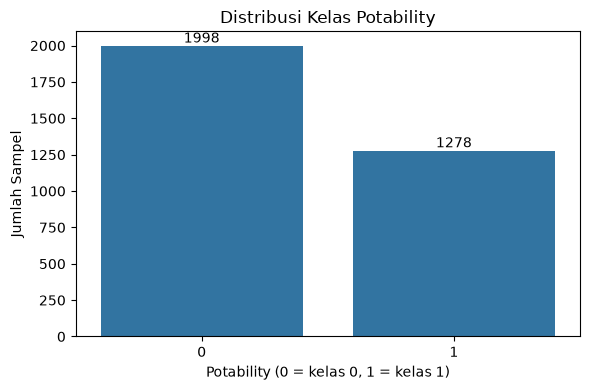

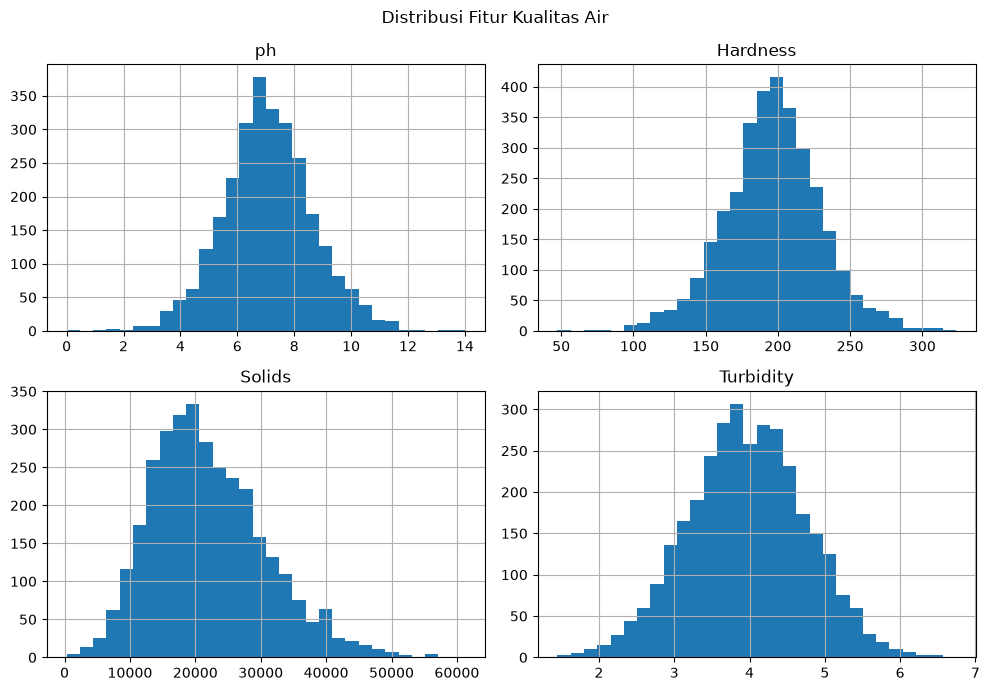

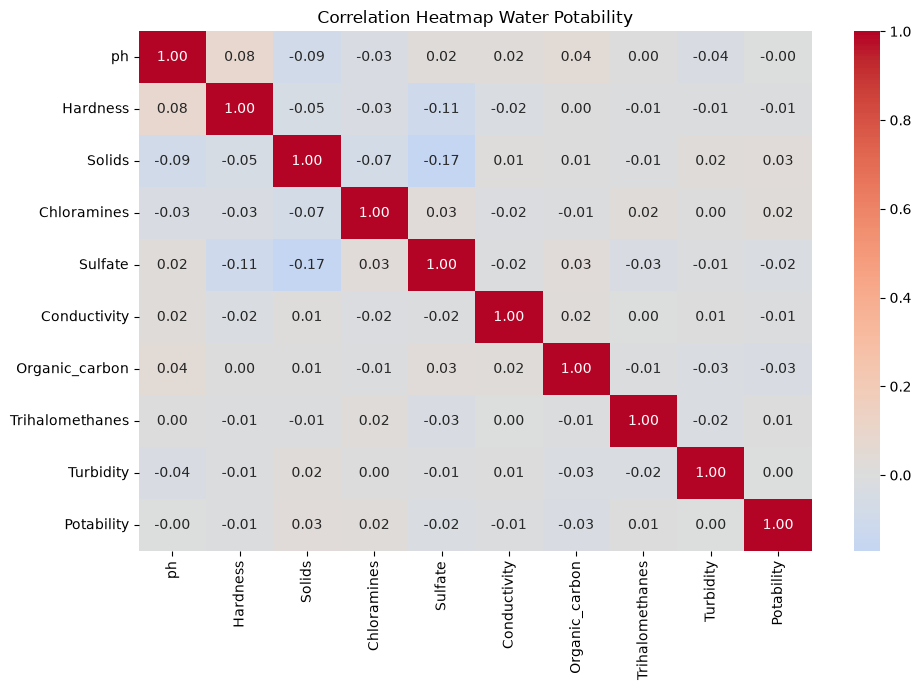

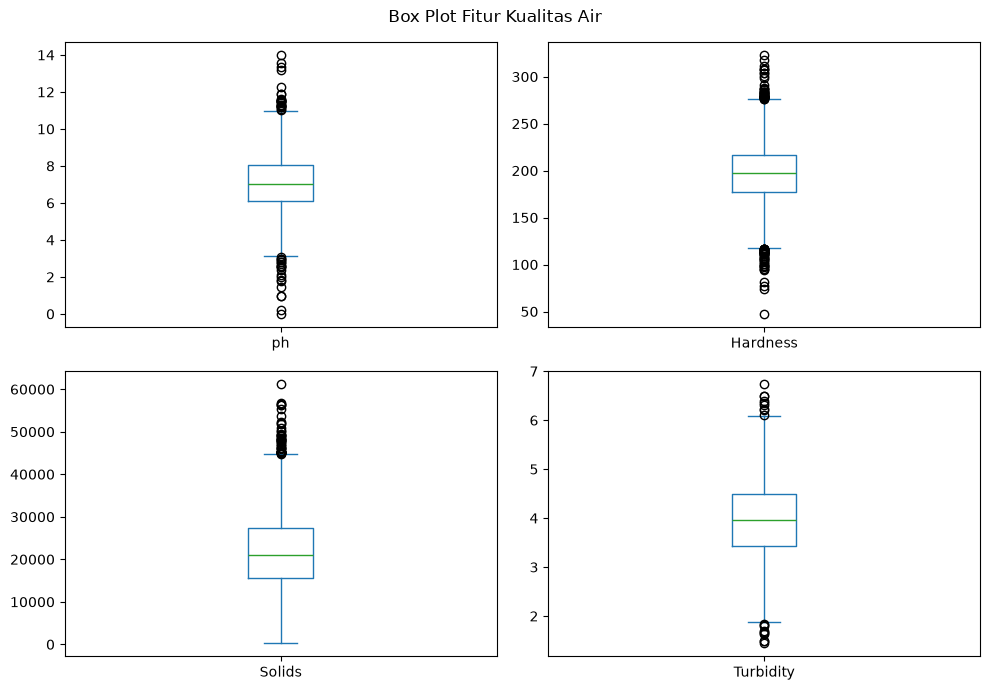

In [6]:
# Soal 1.3: Visualisasi data (minimal 2 grafik)

# Grafik 1: Distribusi target Potability
plt.figure(figsize=(6, 4))

ax = sns.countplot(data=df, x='Potability')

plt.title('Distribusi Kelas Potability')
plt.xlabel('Potability (0 = kelas 0, 1 = kelas 1)')
plt.ylabel('Jumlah Sampel')

# Menampilkan jumlah sampel di atas setiap batang
for bar in ax.patches:
    ax.annotate(
        f'{int(bar.get_height())}',
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        ha='center',
        va='bottom'
    )

plt.tight_layout()
plt.show()


# Grafik 2: Distribusi beberapa fitur numerik
fitur_histogram = ['ph', 'Hardness', 'Solids', 'Turbidity']

df[fitur_histogram].hist(
    figsize=(10, 7),
    bins=30
)

plt.suptitle('Distribusi Fitur Kualitas Air')
plt.tight_layout()
plt.show()


# Grafik 3: Heatmap korelasi
korelasi = df.corr(numeric_only=True)

plt.figure(figsize=(10, 7))

sns.heatmap(
    korelasi,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    center=0
)

plt.title('Correlation Heatmap Water Potability')
plt.tight_layout()
plt.show()


# Grafik tambahan: Pemeriksaan kandidat outliers menggunakan box plot
fitur_boxplot = ['ph', 'Hardness', 'Solids', 'Turbidity']

df[fitur_boxplot].plot(
    kind='box',
    subplots=True,
    layout=(2, 2),
    figsize=(10, 7),
    sharex=False,
    sharey=False
)

plt.suptitle('Box Plot Fitur Kualitas Air')
plt.tight_layout()
plt.show()

**Insight Challenge 1:**

Analisis berdasarkan pertanyaan berikut (min. 4-6 kalimat):

1. **Karakteristik Data**: Berapa jumlah rows/columns? Apa tipe data dari setiap column?
2. **Data Quality**: Apakah ada missing values atau duplicate rows? Jika ada, berapa banyak?
3. **Distribusi Fitur**: Bagaimana distribusi dari fitur-fitur utama? Apakah ada outliers?
4. **Korelasi**: Apakah ada korelasi menarik antara fitur? Fitur mana yang paling berkaitan?




---


Dataset Water Potability terdiri dari 3.276 baris dan 10 kolom, dengan sembilan fitur numerik bertipe `float64` dan satu kolom target `Potability` bertipe `int64`. Pemeriksaan kualitas data menunjukkan terdapat 1.434 missing values, yaitu 491 pada fitur `ph`, 781 pada `Sulfate`, dan 162 pada `Trihalomethanes`, serta tidak ditemukan baris duplikat. Distribusi target terdiri dari 1.998 sampel kelas 0 (61%) dan 1.278 sampel kelas 1 (39%), sehingga distribusi kelas tidak sepenuhnya seimbang. Histogram menunjukkan bahwa fitur `ph`, `Hardness`, dan `Turbidity` memiliki distribusi yang relatif menyerupai bentuk lonceng, sedangkan `Solids` terlihat menceng ke kanan. Box plot menunjukkan adanya kandidat outliers pada keempat fitur yang diperiksa, yaitu `ph`, `Hardness`, `Solids`, dan `Turbidity`; nilai-nilai tersebut perlu dievaluasi lebih lanjut dan tidak langsung dihapus. Berdasarkan korelasi linear dengan target `Potability`, `Solids` memiliki korelasi positif tertinggi sebesar 0,034, sedangkan `Organic_carbon` memiliki korelasi negatif sebesar -0,030; keduanya tetap menunjukkan hubungan linear yang sangat lemah. Temuan ini menjadi dasar untuk menangani missing values, mengevaluasi kandidat outliers, dan membandingkan performa beberapa model klasifikasi pada Challenge 2.

---
<a id='challenge-2'></a>
## Challenge 2 - Machine Learning (Scikit-learn)

**Tujuan:** Melatih dan mengevaluasi model Machine Learning menggunakan Scikit-learn, kemudian membandingkan beberapa pendekatan untuk menentukan model yang paling sesuai dengan dataset dan tujuan prediksi Anda.

### Instruksi
- Pisahkan fitur (X) dan target (y) dari dataset
- **PENTING:** Tentukan variabel target yang ingin diprediksi
- Tentukan jenis masalah Machine Learning berdasarkan target:
  - **Binary Classification** — target memiliki 2 kelas
  - **Multiclass Classification** — target memiliki lebih dari 2 kelas
  - **Regression** — target berupa nilai numerik yang ingin diprediksi
- Bagi data menjadi train/test set (gunakan `random_state=RANDOM_STATE`)
- Pilih dan **bandingkan minimal 2 algoritma** yang sesuai dengan jenis masalah Anda
- Latih model dan evaluasi performanya menggunakan metrik yang sesuai
- Pilih satu model final berdasarkan hasil eksperimen dan alasan yang jelas
- Simpan model final terlatih ke file untuk Challenge 3

> **Catatan penting:** Contoh model di notebook ini adalah panduan, bukan pilihan yang wajib diikuti. Anda bebas mengeksplorasi algoritma lain selama dapat menjelaskan alasan pemilihannya.

### Kriteria Dataset untuk Challenge 2

Pilih dataset yang memungkinkan Anda melakukan **eksperimen Machine Learning** dan menjawab sebuah pertanyaan prediktif.

Dataset yang dipilih sebaiknya:
- Memiliki **target/label yang jelas** dan dapat diprediksi
- Memiliki **fitur yang relevan** untuk digunakan sebagai input model
- Memiliki jumlah observasi yang cukup untuk melakukan training dan testing
- Memiliki kualitas data yang cukup baik untuk dianalisis, atau memiliki masalah data yang dapat Anda tangani melalui preprocessing
- Memungkinkan Anda membandingkan minimal dua model Machine Learning

### Jenis masalah yang dapat dipilih

Anda **bebas memilih jenis masalah sesuai karakteristik dataset**, misalnya:

| Jenis masalah | Contoh target | Contoh algoritma |
|---|---|---|
| **Binary Classification** | 0/1, Yes/No, Positive/Negative | Logistic Regression, Decision Tree, Random Forest, SVM |
| **Multiclass Classification** | A/B/C, Rendah/Sedang/Tinggi | Logistic Regression, Decision Tree, Random Forest, Gradient Boosting |
| **Regression** | Harga, jumlah, skor, pendapatan | Linear Regression, Decision Tree Regressor, Random Forest Regressor, Gradient Boosting Regressor |

> **Tidak ada satu jenis masalah atau algoritma yang diwajibkan.** Pilih pendekatan yang paling sesuai dengan dataset dan pertanyaan yang ingin Anda jawab.

### Evaluasi Model

Metrik evaluasi harus disesuaikan dengan jenis masalah dan karakteristik data.

**Untuk Classification**, Anda dapat menggunakan:
- Accuracy
- Precision
- Recall
- F1-score
- Confusion Matrix

Jika distribusi kelas tidak seimbang (*class imbalance*), **jangan menggunakan accuracy sebagai satu-satunya dasar untuk menilai performa model**.

**Untuk Regression**, Anda dapat menggunakan:
- MAE (Mean Absolute Error)
- RMSE (Root Mean Squared Error)
- R² (R-squared)

> **Yang dinilai bukan seberapa banyak model yang Anda coba, tetapi kemampuan Anda menjelaskan alasan pemilihan model, hasil evaluasi, perbandingan model, dan keterbatasannya.**

In [7]:
# Soal 2.1: Definisikan fitur (X) dan target (y)

TARGET = 'Potability'
PROBLEM_TYPE = 'classification'

# Memisahkan fitur (X) dan target (y)
X = df.drop(columns=[TARGET])
y = df[TARGET]

# Menampilkan fitur
print('=== Fitur (X) ===')
print(list(X.columns))

# Menampilkan informasi target
print('\n=== Target (y) ===')
print(f'Nama target: {TARGET}')
print(f'Tipe data: {y.dtype}')
print(f'Jumlah kelas: {y.nunique()}')

# Menampilkan distribusi jumlah target
print('\n=== Distribusi target ===')
print(y.value_counts(dropna=False))

# Menampilkan proporsi target
print('\n=== Proporsi target ===')
print(y.value_counts(normalize=True, dropna=False).round(3))

# Menampilkan jenis masalah
print('\nJenis masalah:', PROBLEM_TYPE)

=== Fitur (X) ===
['ph', 'Hardness', 'Solids', 'Chloramines', 'Sulfate', 'Conductivity', 'Organic_carbon', 'Trihalomethanes', 'Turbidity']

=== Target (y) ===
Nama target: Potability
Tipe data: int64
Jumlah kelas: 2

=== Distribusi target ===
Potability
0    1998
1    1278
Name: count, dtype: int64

=== Proporsi target ===
Potability
0    0.61
1    0.39
Name: proportion, dtype: float64

Jenis masalah: classification


### Panduan Menentukan Jenis Masalah

Gunakan karakteristik **target (`y`)**, bukan jumlah fitur, untuk menentukan jenis masalah.

- Jika target berupa **kategori/kelas** → **Classification**
  - 2 kelas → Binary Classification
  - >2 kelas → Multiclass Classification
- Jika target berupa **nilai numerik yang ingin diprediksi** → **Regression**

**Tuliskan jawaban Anda:**

> Target yang saya prediksi adalah: `Potability`  
> Jenis masalah saya adalah: `Binary Classification`  
> Alasan: Target Potability memiliki dua kelas, yaitu 0 dan 1. Kelas 0 menunjukkan sampel air yang tidak dapat diminum (not potable), sedangkan kelas 1 menunjukkan sampel air yang dapat diminum (potable). Karena model memprediksi kategori atau kelas, bukan nilai numerik kontinu, masalah ini termasuk binary classification.

---

In [8]:
# Soal 2.2: Split data train/test
# TODO: pilih salah satu pendekatan sesuai jenis masalah Anda.

from sklearn.model_selection import train_test_split

# Menentukan random state
RANDOM_STATE = 1082026

# Membagi data menjadi training dan testing
# stratify=y menjaga proporsi kelas tetap relatif sama
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y
)

# Menampilkan jumlah data
print('=== Jumlah Data ===')
print('Jumlah data awal:', len(X))
print('Jumlah data training:', len(X_train))
print('Jumlah data testing:', len(X_test))

# Memeriksa proporsi kelas pada data training
print('\n=== Proporsi Kelas Data Training ===')
print(y_train.value_counts(normalize=True).round(3))

# Memeriksa proporsi kelas pada data testing
print('\n=== Proporsi Kelas Data Testing ===')
print(y_test.value_counts(normalize=True).round(3))

=== Jumlah Data ===
Jumlah data awal: 3276
Jumlah data training: 2620
Jumlah data testing: 656

=== Proporsi Kelas Data Training ===
Potability
0    0.61
1    0.39
Name: proportion, dtype: float64

=== Proporsi Kelas Data Testing ===
Potability
0    0.61
1    0.39
Name: proportion, dtype: float64


### Catatan tentang `stratify`

`stratify=y` digunakan pada **classification** untuk membantu mempertahankan proporsi kelas yang kurang lebih sama pada data training dan testing.

Contoh:

Jika data awal memiliki sekitar 70% kelas 0 dan 30% kelas 1, maka dengan stratified split proporsinya akan dibuat kurang lebih sama pada train dan test.

> Untuk **regression**, jangan menggunakan `stratify=y`.

## 2.3 Pemilihan dan Eksplorasi Model

Anda **bebas memilih dan membandingkan model** sesuai dengan jenis masalah Anda.

### Contoh untuk Classification

**Baseline / model sederhana:**
- Logistic Regression
- K-Nearest Neighbors

**Tree-based:**
- Decision Tree
- Random Forest

**Ensemble / boosting:**
- Gradient Boosting
- HistGradientBoosting

**Model lainnya:**
- Support Vector Machine
- Naive Bayes

### Contoh untuk Regression

**Baseline / model sederhana:**
- Linear Regression
- Ridge / Lasso

**Tree-based:**
- Decision Tree Regressor
- Random Forest Regressor

**Ensemble / boosting:**
- Gradient Boosting Regressor
- HistGradientBoosting Regressor

### Ketentuan

Minimal bandingkan **2 model**:
1. Satu model sebagai **baseline**
2. Satu model alternatif

Anda boleh mencoba model ketiga atau model lainnya jika ingin melakukan eksplorasi lebih lanjut.

> **Contoh pada kasus binary classification:** Logistic Regression dapat digunakan sebagai baseline dan Random Forest sebagai model alternatif. Namun, **Anda tidak diwajibkan menggunakan kedua model tersebut**.

Yang penting, Anda dapat menjelaskan:
1. Mengapa model tersebut dipilih?
2. Bagaimana performanya?
3. Apa kelebihan dan keterbatasannya?
4. Mengapa akhirnya memilih model tertentu sebagai model final?

In [10]:
# Soal 2.3: Latih model
# TODO:
# Buat dan latih minimal 2 model.

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

# Model 1: Logistic Regression (baseline)
model_baseline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression(
        random_state=RANDOM_STATE,
        max_iter=1000
    ))
])

# Model 2: Decision Tree (alternatif)
model_alternatif = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('classifier', DecisionTreeClassifier(
        random_state=RANDOM_STATE,
        max_depth=5
    ))
])

# Melatih kedua model menggunakan data training
model_baseline.fit(X_train, y_train)
model_alternatif.fit(X_train, y_train)

print("Logistic Regression berhasil dilatih.")
print("Decision Tree berhasil dilatih.")

Logistic Regression berhasil dilatih.
Decision Tree berhasil dilatih.


## 2.4 Evaluasi dan Perbandingan Model

Evaluasi semua model menggunakan **metrik yang sesuai dengan jenis masalah**.

### Jika Classification

Gunakan beberapa metrik yang relevan:
- **Accuracy** — proporsi prediksi yang benar secara keseluruhan
- **Precision** — proporsi prediksi positif yang benar
- **Recall** — proporsi kasus positif yang berhasil ditemukan
- **F1-score** — keseimbangan precision dan recall
- **Confusion Matrix** — melihat jenis kesalahan prediksi

Jika data memiliki **class imbalance**, jangan hanya melihat accuracy.

### Jika Regression

Gunakan beberapa metrik yang relevan:
- **MAE** — rata-rata besar kesalahan absolut
- **RMSE** — memberi penalti lebih besar pada error yang besar
- **R²** — seberapa baik model menjelaskan variasi target

> Jangan hanya mencari angka tertinggi. Pahami apa arti setiap metrik dalam konteks masalah Anda.

=== Perbandingan Model ===


,Model,Train Accuracy,Test Accuracy,Balanced Accuracy,Precision,Recall,F1-score
1,Decision Tree,0.691,0.625,0.560,0.54,0.262,0.353
0,Logistic Regression,0.610,0.608,0.499,0.00,0.000,0.000



=== Classification Report: Logistic Regression ===
                   precision    recall  f1-score   support

Tidak Potable (0)       0.61      1.00      0.76       400
      Potable (1)       0.00      0.00      0.00       256

         accuracy                           0.61       656
        macro avg       0.30      0.50      0.38       656
     weighted avg       0.37      0.61      0.46       656


=== Confusion Matrix: Logistic Regression ===
[[399   1]
 [256   0]]


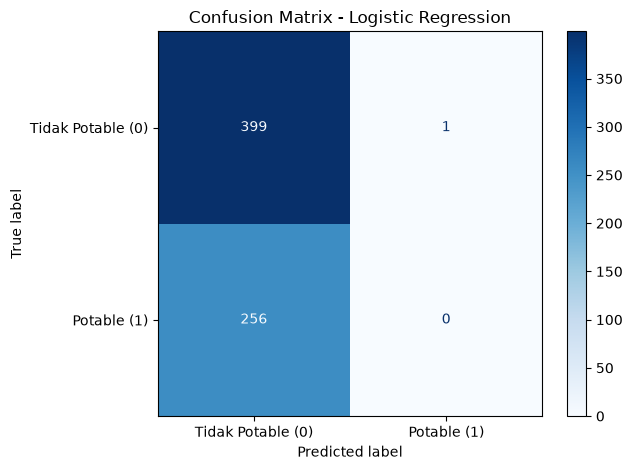


=== Classification Report: Decision Tree ===
                   precision    recall  f1-score   support

Tidak Potable (0)       0.64      0.86      0.74       400
      Potable (1)       0.54      0.26      0.35       256

         accuracy                           0.62       656
        macro avg       0.59      0.56      0.54       656
     weighted avg       0.60      0.62      0.59       656


=== Confusion Matrix: Decision Tree ===
[[343  57]
 [189  67]]


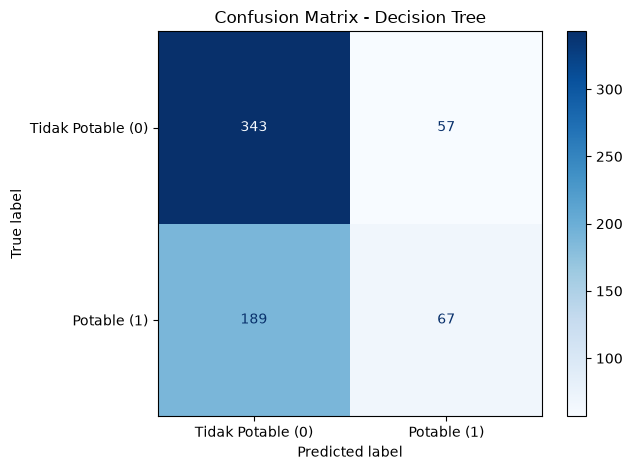

In [11]:
# Soal 2.4: Evaluasi model

# TODO:
# Evaluasi semua model yang Anda buat.
# Buat tabel perbandingan hasil agar mudah dianalisis.

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

# Daftar model yang akan dievaluasi
models = {
    'Logistic Regression': model_baseline,
    'Decision Tree': model_alternatif
}

hasil_evaluasi = []

# Menghitung metrik evaluasi setiap model
for nama, model_uji in models.items():
    pred_train = model_uji.predict(X_train)
    pred_test = model_uji.predict(X_test)

    hasil_evaluasi.append({
        'Model': nama,
        'Train Accuracy': accuracy_score(y_train, pred_train),
        'Test Accuracy': accuracy_score(y_test, pred_test),
        'Balanced Accuracy': balanced_accuracy_score(
            y_test, pred_test
        ),
        'Precision': precision_score(
            y_test, pred_test, zero_division=0
        ),
        'Recall': recall_score(
            y_test, pred_test, zero_division=0
        ),
        'F1-score': f1_score(
            y_test, pred_test, zero_division=0
        )
    })

# Membuat tabel perbandingan hasil evaluasi
tabel_evaluasi = pd.DataFrame(hasil_evaluasi)

print('=== Perbandingan Model ===')
display(
    tabel_evaluasi.round(3).sort_values(
        by='F1-score',
        ascending=False
    )
)

# Menampilkan classification report dan confusion matrix
for nama, model_uji in models.items():
    pred_test = model_uji.predict(X_test)

    print(f'\n=== Classification Report: {nama} ===')
    print(classification_report(
        y_test,
        pred_test,
        zero_division=0,
        target_names=['Tidak Potable (0)', 'Potable (1)']
    ))

    print(f'\n=== Confusion Matrix: {nama} ===')
    print(confusion_matrix(y_test, pred_test))

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        pred_test,
        display_labels=['Tidak Potable (0)', 'Potable (1)'],
        cmap='Blues'
    )

    plt.title(f'Confusion Matrix - {nama}')
    plt.tight_layout()
    plt.show()

### Analisis Confusion Matrix — khusus Classification

Karena proyek ini menggunakan *binary classification* untuk memprediksi label `Potability`, analisis confusion matrix digunakan untuk mengevaluasi hasil prediksi dua kelas:

- **Kelas 0:** Tidak Potable menurut label dataset.
- **Kelas 1:** Potable menurut label dataset.

Confusion matrix untuk model yang diuji adalah sebagai berikut.

**Logistic Regression**

| | Predicted 0 | Predicted 1 |
|---|---:|---:|
| **Actual 0** | TN = 399 | FP = 1 |
| **Actual 1** | FN = 256 | TP = 0 |

**Decision Tree**

| | Predicted 0 | Predicted 1 |
|---|---:|---:|
| **Actual 0** | TN = 343 | FP = 57 |
| **Actual 1** | FN = 189 | TP = 67 |

Keterangan:
- **TN (True Negative):** Sampel kelas 0 yang diprediksi sebagai kelas 0 dengan benar.
- **FP (False Positive):** Sampel kelas 0 yang salah diprediksi sebagai kelas 1.
- **FN (False Negative):** Sampel kelas 1 yang salah diprediksi sebagai kelas 0.
- **TP (True Positive):** Sampel kelas 1 yang diprediksi sebagai kelas 1 dengan benar.

**1. Kelas mana yang paling mudah dikenali?**

Kelas 0 (*Tidak Potable*) lebih mudah dikenali oleh kedua model. Logistic Regression berhasil mengklasifikasikan dengan benar 399 dari 400 sampel kelas 0, dengan *recall* sebesar 99,75%. Sementara itu, Decision Tree berhasil mengklasifikasikan dengan benar 343 dari 400 sampel kelas 0, dengan *recall* sebesar 85,75%. Hasil ini menunjukkan bahwa kedua model lebih baik dalam mengenali kelas 0 dibandingkan kelas 1.

**2. Kelas mana yang paling sering salah diprediksi?**

Kelas 1 (*Potable*) paling sering salah diprediksi sebagai kelas 0. Logistic Regression salah mengklasifikasikan seluruh 256 sampel kelas 1, sehingga *recall* kelas 1 adalah 0%. Sementara itu, Decision Tree salah mengklasifikasikan 189 dari 256 sampel kelas 1 dan berhasil mengenali 67 sampel dengan benar. Dengan demikian, Decision Tree lebih baik daripada Logistic Regression dalam mengenali kelas 1, meskipun performanya masih terbatas.

**3. Apakah false positive atau false negative lebih penting dalam use case ini?**

Dalam konteks prediksi potabilitas air, *false positive* perlu mendapat perhatian khusus karena sampel yang sebenarnya berlabel tidak potable (kelas 0) diprediksi sebagai potable (kelas 1). Kesalahan ini berpotensi menimbulkan rasa aman yang keliru jika hasil model dianggap sebagai bukti bahwa air aman diminum. *False negative* juga perlu diperhatikan karena sampel yang sebenarnya berlabel potable (kelas 1) diprediksi sebagai tidak potable (kelas 0), sehingga dapat menimbulkan kekhawatiran atau tindakan yang tidak diperlukan.

**4. Apa konsekuensi kesalahan tersebut?**

Kesalahan klasifikasi dapat menyebabkan keputusan yang keliru terkait kualitas air. Logistic Regression tidak berhasil mengenali satu pun sampel kelas 1 pada data pengujian, sedangkan Decision Tree berhasil mengenali 67 sampel kelas 1, tetapi masih menghasilkan 189 *false negative*. Oleh karena itu, kedua model masih memiliki keterbatasan dan belum layak dijadikan dasar tunggal untuk menentukan keamanan air minum. Hasil prediksi merupakan bagian dari eksperimen pembelajaran dan tidak menggantikan pengujian kualitas air yang sesuai.

### Overfitting / Underfitting

Analisis dilakukan dengan membandingkan *train accuracy* dan *test accuracy* dari Logistic Regression dan Decision Tree.

| Model | Train Accuracy | Test Accuracy | Selisih | Interpretasi |
|---|---:|---:|---:|---|
| Logistic Regression | 0,610 | 0,608 | 0,002 | Tidak menunjukkan indikasi overfitting yang jelas. Performa yang relatif rendah pada data training dan testing mengindikasikan kemungkinan underfitting. |
| Decision Tree | 0,691 | 0,625 | 0,066 | Terdapat indikasi overfitting karena performa training lebih tinggi daripada testing, tetapi belum cukup untuk memastikan overfitting yang serius. |

**Analisis hasil eksperimen:**

Logistic Regression memiliki *train accuracy* sebesar 0,610 dan *test accuracy* sebesar 0,608, dengan selisih hanya 0,002. Kedua nilai tersebut relatif rendah dan hampir sama, sehingga tidak terdapat indikasi overfitting yang jelas. Hasil ini mengindikasikan kemungkinan underfitting, yaitu model belum mampu mempelajari pola data dengan baik. Hal ini juga didukung oleh hasil evaluasi sebelumnya, ketika Logistic Regression tidak berhasil mengenali satu pun sampel kelas 1 pada data pengujian.

Decision Tree memiliki *train accuracy* sebesar 0,691 dan *test accuracy* sebesar 0,625, dengan selisih 0,066. Performa pada data training lebih tinggi daripada data testing, sehingga terdapat indikasi bahwa model mempelajari pola yang lebih sesuai dengan data training dibandingkan data yang belum pernah dilihat. Namun, selisih ini belum cukup untuk menyimpulkan bahwa model mengalami overfitting yang serius.

**Kesimpulan:**

Decision Tree memberikan *test accuracy* yang lebih tinggi daripada Logistic Regression, yaitu 0,625 dibandingkan 0,608. Meskipun demikian, kemampuan kedua model masih terbatas, terutama dalam mengenali kelas 1. Oleh karena itu, Decision Tree dipilih sebagai model yang lebih baik di antara kedua model yang diuji, tetapi masih diperlukan evaluasi dan pengembangan lebih lanjut untuk meningkatkan performanya.

### Feature Importance / Model Interpretation

Jika model Anda mendukung interpretasi fitur, analisis fitur yang paling berpengaruh.

Contoh:
- Random Forest → `feature_importances_`
- Linear/Logistic Regression → koefisien
- Model lain → gunakan metode interpretasi yang sesuai

> **Catatan:** Feature importance tidak otomatis berarti hubungan sebab-akibat.

Jika model tidak memiliki feature importance secara langsung, Anda dapat menggunakan permutation importance atau menjelaskan keterbatasan interpretasinya.

,Feature,Importance
0,ph,0.3285
1,Solids,0.1707
2,Sulfate,0.1703
3,Hardness,0.1206
4,Chloramines,0.0944
5,Conductivity,0.0499
6,Organic_carbon,0.0274
7,Trihalomethanes,0.0191
8,Turbidity,0.0191


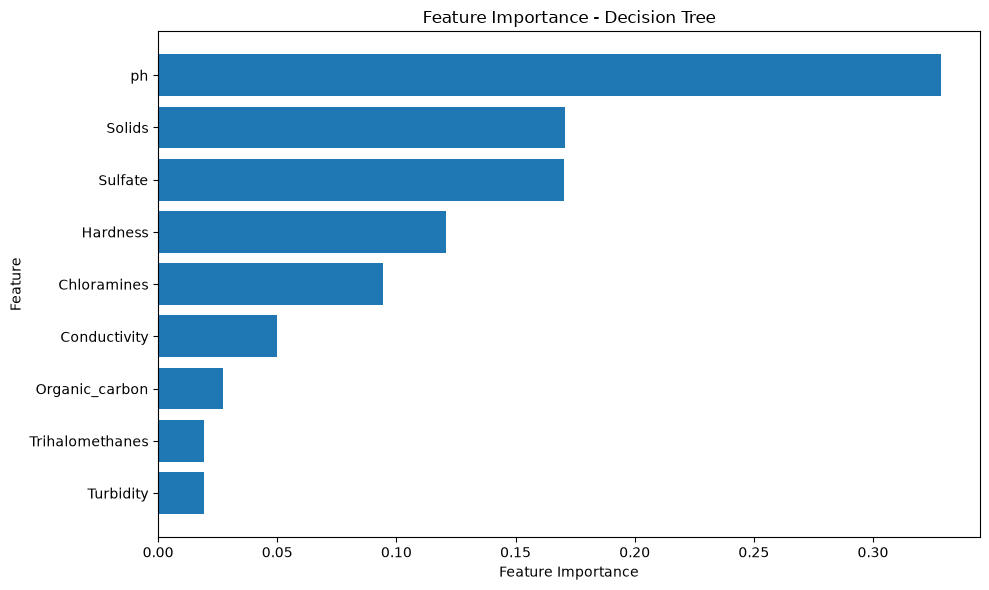

In [14]:
# Feature Importance: Decision Tree

feature_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': model_alternatif.named_steps['classifier'].feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
).reset_index(drop=True)

display(feature_importance.round(4))

# Visualisasi Feature Importance
plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance['Feature'],
    feature_importance['Importance']
)

plt.xlabel('Feature Importance')
plt.ylabel('Feature')
plt.title('Feature Importance - Decision Tree')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

## 2.5 Memilih Model Final

Setelah membandingkan model, pilih **satu model final** untuk digunakan pada Challenge 3.

Pertimbangkan:
- Performa pada metrik utama
- Keseimbangan beberapa metrik
- Interpretabilitas
- Kompleksitas model
- Kecepatan
- Kebutuhan preprocessing
- Risiko overfitting
- Konteks penggunaan

**Model final yang saya pilih:** `Decision Tree`

**Alasan:**

Saya memilih Decision Tree karena menunjukkan hasil evaluasi yang relatif lebih baik dibandingkan Logistic Regression pada data pengujian. Decision Tree memperoleh test accuracy sebesar 0,625, F1-score kelas 1 sebesar 0,353, dan balanced accuracy sebesar 0,560. Sementara itu, Logistic Regression memperoleh test accuracy sebesar 0,608, F1-score kelas 1 sebesar 0,000, dan balanced accuracy sebesar 0,499.

Berdasarkan confusion matrix, Decision Tree berhasil memprediksi dengan benar 67 sampel kelas 1, sedangkan Logistic Regression tidak berhasil mengenali satu pun sampel kelas 1 dengan benar. Hal ini menunjukkan bahwa Decision Tree lebih mampu mengenali kelas 1 pada pengujian ini, meskipun recall kelas 1 masih rendah, yaitu 0,262. Dengan kata lain, model hanya berhasil mengenali sekitar 26,2% dari seluruh sampel kelas 1 pada data pengujian.

Selain itu, Decision Tree menyediakan feature_importances_ yang dapat digunakan untuk memahami kontribusi relatif setiap fitur dalam proses prediksi. Model ini juga menggunakan batas kedalaman pohon (max_depth=5) untuk membatasi kompleksitasnya.

Meskipun demikian, selisih train accuracy dan test accuracy sebesar 0,066 menunjukkan adanya indikasi kemungkinan overfitting, tetapi belum cukup untuk memastikannya. Test accuracy sebesar 0,625 dan recall kelas 1 yang masih rendah juga menunjukkan bahwa kemampuan prediksi model masih terbatas.

Oleh karena itu, Decision Tree dipilih sebagai model final untuk eksperimen pada Challenge 3 karena memberikan hasil evaluasi yang lebih baik di antara dua model yang dibandingkan, dengan tetap mempertimbangkan keterbatasannya. Model ini digunakan untuk keperluan pembelajaran dan eksperimen, bukan sebagai alat untuk memastikan keamanan air minum secara langsung.

In [15]:
# Soal 2.5: Simpan model final
# Ganti `model_final` dengan model yang Anda pilih sebagai model final.

# Memilih Decision Tree sebagai model final
model_final = model_alternatif

# Menentukan lokasi penyimpanan model
path_model = '/content/model.pkl'

# Menyimpan model final
joblib.dump(model_final, path_model)

print('Model final: Decision Tree')
print('Model berhasil disimpan di:', path_model)

Model final: Decision Tree
Model berhasil disimpan di: /content/model.pkl


**Insight Challenge 2:**

Analisis hasil eksperimen berdasarkan pertanyaan berikut (min. 5-7 kalimat):

1. **Jenis Masalah**: Apa target yang diprediksi dan mengapa masalah Anda termasuk classification atau regression?
2. **Pemilihan Model**: Model apa saja yang dibandingkan? Mengapa model tersebut dipilih?
3. **Performa Model**: Bagaimana hasil masing-masing model berdasarkan metrik yang digunakan?
4. **Kesalahan Model**: Jika classification, apa yang terlihat dari confusion matrix? Jika regression, bagaimana pola error atau nilai MAE/RMSE?
5. **Overfitting/Underfitting**: Apakah terdapat indikasi overfitting atau underfitting?
6. **Feature Importance / Interpretasi**: Fitur mana yang paling berpengaruh jika dapat dianalisis?
7. **Model Final**: Model mana yang akhirnya dipilih dan mengapa?
8. **Langkah Improvement**: Apa yang dapat dilakukan untuk meningkatkan performa model?


---


**Insight Challenge 2**

Eksperimen ini bertujuan memprediksi **potabilitas air**, yaitu apakah sampel air termasuk kategori tidak potable (0) atau potable (1) berdasarkan label dalam dataset. Masalah ini termasuk *classification* karena model memprediksi kategori, bukan nilai numerik kontinu. Dua model yang dibandingkan adalah Logistic Regression sebagai model baseline dan Decision Tree sebagai model alternatif untuk mengetahui perbedaan performa keduanya.

Berdasarkan hasil pengujian, Logistic Regression memperoleh *test accuracy* sebesar 0,608, sedangkan Decision Tree memperoleh 0,625. Decision Tree juga menghasilkan *F1-score* kelas 1 sebesar 0,353 dan *balanced accuracy* sebesar 0,560, lebih tinggi daripada Logistic Regression yang masing-masing memperoleh 0,000 dan 0,499. Berdasarkan *confusion matrix*, Logistic Regression salah mengklasifikasikan satu sampel kelas 0 sebagai kelas 1 dan tidak berhasil mengenali sampel kelas 1 dengan benar. Sementara itu, Decision Tree berhasil mengenali 67 sampel kelas 1, tetapi masih salah mengklasifikasikan 189 sampel kelas 1 sebagai kelas 0. Hasil ini menunjukkan bahwa kedua model masih memiliki keterbatasan dalam mengenali kelas 1, terutama Logistic Regression.

Dari perbandingan akurasi training dan testing, Logistic Regression memiliki selisih sebesar 0,002, sedangkan Decision Tree memiliki selisih sebesar 0,066. Selisih pada Decision Tree menunjukkan kemungkinan adanya *overfitting*, tetapi belum cukup untuk memastikan bahwa model mengalami *overfitting* yang serius.

Berdasarkan analisis *feature importance* pada Decision Tree, fitur **ph** memiliki nilai kepentingan tertinggi sebesar 0,3285, diikuti oleh **Solids** sebesar 0,1707 dan **Sulfate** sebesar 0,1703. Fitur dengan nilai terendah adalah **Trihalomethanes** dan **Turbidity**, masing-masing sebesar 0,0191. Hasil ini menunjukkan fitur mana yang paling banyak digunakan atau berkontribusi dalam proses pengambilan keputusan model Decision Tree. Namun, *feature importance* tidak membuktikan hubungan sebab-akibat dan tidak berarti fitur dengan nilai tertinggi selalu menjadi faktor utama penentu keamanan air.

Berdasarkan hasil evaluasi tersebut, saya memilih Decision Tree sebagai model final untuk eksperimen berikutnya karena memiliki *test accuracy*, *F1-score* kelas 1, dan *balanced accuracy* yang lebih baik daripada Logistic Regression. Meskipun demikian, performa Decision Tree masih perlu ditingkatkan karena *recall* kelas 1 hanya sebesar 0,262. Untuk meningkatkan performa model, eksperimen selanjutnya dapat mencoba penyesuaian parameter, penanganan ketidakseimbangan kelas, dan evaluasi menggunakan *cross-validation*. Model ini masih merupakan eksperimen pembelajaran dan tidak dapat digunakan sebagai satu-satunya dasar untuk menentukan apakah air aman diminum.

---
<a id='challenge-3'></a>
## Challenge 3 - Prediction

**Tujuan:** Menggunakan model yang telah dilatih untuk memprediksi data baru yang belum pernah dilihat.

### Instruksi
- Muat kembali model yang sudah disimpan di Challenge 2
- Buat 2-3 contoh data baru dengan fitur yang sama dengan X
- Lakukan prediksi dan tampilkan hasilnya; jika model mendukung `predict_proba`, tampilkan probability/confidence scores

In [16]:
# Soal 3.1: Muat model (jika perlu, jika di-run terpisah dari Challenge 2)

model = joblib.load('/content/model.pkl')

print('✓ Model final berhasil dimuat')

✓ Model final berhasil dimuat


In [17]:
# Soal 3.2: Membuat 3 contoh data baru untuk prediksi

data_baru = pd.DataFrame({
    'ph': [7.0, 5.5, 8.5],
    'Hardness': [200.0, 180.0, 250.0],
    'Solids': [15000.0, 30000.0, 40000.0],
    'Chloramines': [7.0, 4.0, 9.0],
    'Sulfate': [300.0, 200.0, 350.0],
    'Conductivity': [400.0, 500.0, 600.0],
    'Organic_carbon': [10.0, 15.0, 20.0],
    'Trihalomethanes': [60.0, 40.0, 90.0],
    'Turbidity': [3.0, 5.0, 6.0]
})

print('DATA BARU UNTUK DIPREDIKSI:')
print('=' * 70)
print(data_baru.to_string(index=False))

print('\nJumlah sampel:', len(data_baru))
print('\nUrutan kolom:', data_baru.columns.tolist())

DATA BARU UNTUK DIPREDIKSI:
 ph  Hardness  Solids  Chloramines  Sulfate  Conductivity  Organic_carbon  Trihalomethanes  Turbidity
7.0     200.0 15000.0          7.0    300.0         400.0            10.0             60.0        3.0
5.5     180.0 30000.0          4.0    200.0         500.0            15.0             40.0        5.0
8.5     250.0 40000.0          9.0    350.0         600.0            20.0             90.0        6.0

Jumlah sampel: 3

Urutan kolom: ['ph', 'Hardness', 'Solids', 'Chloramines', 'Sulfate', 'Conductivity', 'Organic_carbon', 'Trihalomethanes', 'Turbidity']


In [19]:
# Soal 3.3: Melakukan prediksi dan menampilkan hasil

model = model_alternatif

# Melakukan prediksi pada tiga sampel
hasil_prediksi = model.predict(data_baru)

# Menyalin data input dan menambahkan hasil prediksi
hasil = data_baru.copy()
hasil['Prediksi_Potability'] = hasil_prediksi

# Menampilkan probabilitas jika model mendukungnya
if hasattr(model, 'predict_proba'):
    probabilitas = model.predict_proba(data_baru)

    for indeks, kelas in enumerate(model.classes_):
        hasil[f'Probabilitas_Kelas_{kelas}'] = probabilitas[:, indeks]

# Menampilkan hasil
print('HASIL PREDIKSI POTABILITAS AIR')
print('=' * 70)
display(hasil.round(3))

HASIL PREDIKSI POTABILITAS AIR


,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Prediksi_Potability,Probabilitas_Kelas_0,Probabilitas_Kelas_1
0,7.0,200.0,15000.0,7.0,300.0,400.0,10.0,60.0,3.0,0,0.659,0.341
1,5.5,180.0,30000.0,4.0,200.0,500.0,15.0,40.0,5.0,1,0.000,1.000
2,8.5,250.0,40000.0,9.0,350.0,600.0,20.0,90.0,6.0,1,0.364,0.636


## Analisis Tambahan: Pemeriksaan Leaf Decision Tree

In [20]:
# Mengambil Decision Tree yang sudah dilatih
pohon = model_alternatif.named_steps['classifier']

# Mengubah data baru dengan imputer yang sudah dilatih
data_imputasi = model_alternatif.named_steps['imputer'].transform(data_baru)

# Menemukan daun yang dicapai setiap sampel
daun = pohon.apply(data_imputasi)

# Melihat jumlah sampel training dari setiap kelas pada daun
for i, nomor_daun in enumerate(daun):
    jumlah_kelas = pohon.tree_.value[nomor_daun][0]
    total = jumlah_kelas.sum()

    print(f'Sampel {i + 1}:')
    print(f'Nomor daun: {nomor_daun}')
    print(f'Jumlah kelas 0: {jumlah_kelas[0]:.0f}')
    print(f'Jumlah kelas 1: {jumlah_kelas[1]:.0f}')
    print(f'Total sampel pada daun: {total:.0f}')
    print()

Sampel 1:
Nomor daun: 30
Jumlah kelas 0: 1
Jumlah kelas 1: 0
Total sampel pada daun: 1

Sampel 2:
Nomor daun: 13
Jumlah kelas 0: 0
Jumlah kelas 1: 1
Total sampel pada daun: 1

Sampel 3:
Nomor daun: 41
Jumlah kelas 0: 0
Jumlah kelas 1: 1
Total sampel pada daun: 1



## Interpretasi Prediksi

Model final, yaitu Decision Tree, digunakan untuk menghasilkan prediksi terhadap tiga sampel simulasi kualitas air yang dibuat secara manual. Hasil prediksi menunjukkan bahwa sampel pertama diklasifikasikan sebagai kelas 0 (*tidak potable*), sedangkan sampel kedua dan ketiga diklasifikasikan sebagai kelas 1 (*potable*) berdasarkan label dalam dataset.

Pada sampel pertama, model memberikan probabilitas kelas 0 sebesar 65,9% dan kelas 1 sebesar 34,1%. Pada sampel kedua, probabilitas kelas 1 mencapai 100%, sedangkan pada sampel ketiga probabilitas kelas 1 sebesar 63,6%. Hasil pemeriksaan leaf menunjukkan bahwa setiap sampel mencapai leaf yang tercatat memiliki satu sampel training. Jika angka tersebut memang merepresentasikan jumlah sampel pada leaf, hal ini membantu menjelaskan mengapa model memberikan probabilitas penuh kepada kelas yang diprediksi pada sampel kedua. Namun, probabilitas 100% tidak menjamin bahwa prediksi tersebut benar, terutama ketika prediksi didasarkan pada leaf dengan jumlah sampel training yang sangat sedikit.

Eksperimen ini menunjukkan bagaimana Decision Tree menghasilkan prediksi berdasarkan kombinasi nilai fitur yang diberikan. Hasil pemeriksaan leaf juga menjadi pengingat bahwa kompleksitas pohon dan kemampuan model untuk melakukan generalisasi perlu diperhatikan. Pengembangan berikutnya dapat mencakup penyesuaian parameter model dan evaluasi menggunakan *cross-validation*.

Ketiga sampel yang digunakan merupakan data simulasi, bukan hasil pengukuran kualitas air yang sebenarnya. Oleh karena itu, hasil prediksi ini hanya digunakan untuk demonstrasi pembelajaran dan tidak dapat dijadikan bukti bahwa air aman atau tidak aman untuk diminum. Penentuan keamanan air memerlukan pemeriksaan kualitas air yang sesuai.

---
<a id='challenge-4'></a>
## Challenge 4 - Integrasi Gemini API

**Tujuan:** Menggunakan Gemini API untuk menjelaskan hasil prediksi dengan bahasa natural yang mudah dipahami.
- Install Google AI library: `pip install google-generativeai python-dotenv`

In [21]:
# Soal 4.1: Setup Gemini API

from pathlib import Path
from dotenv import load_dotenv
from google import genai

# Menentukan folder utama proyek
PROJECT_ROOT = Path.cwd().parent

# Memuat API key dari file .env
load_dotenv(PROJECT_ROOT / '.env')

API_KEY = os.getenv('GEMINI_API_KEY')

if not API_KEY:
    raise ValueError(
        '⚠️ ERROR: GEMINI_API_KEY tidak ditemukan!'
        'Pastikan file .env berada di folder utama proyek '
        'dan berisi API key yang valid.'
    )

# Membuat client Gemini
client = genai.Client(api_key=API_KEY)

print('✓ Gemini API client berhasil disiapkan.')

✓ Gemini API client berhasil disiapkan.


In [23]:
# Inisialisasi Model Generatif Gemini

# Inisialisasi Model Generatif Gemini 3 Flash Preview
NAMA_MODEL_GEMINI = 'gemini-3.6-flash'

print('Model yang dipilih:', NAMA_MODEL_GEMINI)

Model yang dipilih: gemini-3.6-flash


In [28]:
# Soal 4.2: Susun prompt dan minta penjelasan dari Gemini

# Membuat prompt untuk Gemini berdasarkan hasil prediksi aktual
prompt = f"""\
Anda membantu menjelaskan output model machine learning untuk audiens non-teknis.

Data prediksi berikut berasal dari model Decision Tree yang memprediksi label Potability berdasarkan fitur numerik pada dataset Water Potability.
Label 0 berarti tidak potable dan label 1 berarti potable menurut kategori pada dataset. Data berikut merupakan sampel simulasi untuk keperluan pembelajaran, bukan hasil pengukuran kualitas air yang sebenarnya.

Data hasil prediksi:
{hasil.to_string(index=False)}

Jelaskan hasil prediksi model klasifikasi kualitas air dalam bahasa Indonesia yang sederhana, singkat, netral, dan mudah dipahami.
Untuk setiap sampel:
1. Sebutkan kelas yang diprediksi dan jelaskan artinya berdasarkan label pada dataset.
2. Jika probabilitas tersedia, gunakan istilah "Estimasi Probabilitas Model". Jelaskan bahwa angka tersebut merupakan estimasi model untuk kelas yang diprediksi, bukan jaminan bahwa prediksi benar. Probabilitas 100% juga bukan kepastian bahwa prediksi benar atau air aman untuk dikonsumsi.
3. Jangan mengarang hubungan sebab-akibat antara fitur kualitas air dan hasil prediksi. Jelaskan bahwa prediksi didasarkan pada pola yang dipelajari model.
4. Jangan menyimpulkan bahwa air pasti aman atau tidak aman untuk dikonsumsi hanya berdasarkan prediksi.
5. Gunakan hanya informasi yang tersedia dalam data. Jangan mengarang nilai, fitur, atau penjelasan tambahan.

Format jawaban:
- Awali dengan judul "Penjelasan Hasil Prediksi Model" dan satu kalimat pengantar.
- Jelaskan setiap sampel secara terpisah dengan format:
  Sampel [nomor]
  - Hasil Prediksi: kelas dan arti labelnya.
  - Estimasi Probabilitas Model: nilai probabilitas dan penjelasan singkatnya, jika tersedia.
- Akhiri dengan bagian Catatan Penting dalam bentuk poin yang menjelaskan bahwa hasil prediksi dapat salah, tidak membuktikan hubungan sebab-akibat, dan bukan pengganti pengujian kualitas air menggunakan metode yang sesuai.

Jangan menambahkan diagnosis, rekomendasi konsumsi air, atau klaim keamanan air yang tidak didukung oleh data.
"""

# Daftar model utama dan model cadangan (fallback) jika terjadi error 503 / sibuk
DAFTAR_MODEL = [
    NAMA_MODEL_GEMINI,
    'gemini-3.8-flash',
    'gemini-3.7-flash',
    'gemini-3.1-pro'
]

penjelasan_gemini = None
berhasil = False

for model_pilihan in DAFTAR_MODEL:
    try:
        print(f'Mencoba menggunakan model: {model_pilihan}...')
        response = client.models.generate_content(
            model=model_pilihan,
            contents=prompt
        )
        penjelasan_gemini = response.text
        berhasil = True
        print(f'Berhasil menggunakan model: {model_pilihan}')
        break # Berhenti looping jika berhasil
        
    except Exception as e:
        print(f'Gagal dengan model {model_pilihan}: {e}')
        print('Mencoba beralih ke model cadangan berikutnya...\n')

# Jika semua model gagal
if not berhasil:
    penjelasan_gemini = 'Gemini API error: Semua model cadangan sedang mengalami gangguan atau high demand.'

print('\n' + '=' * 80)
print('AI-GENERATED EXPLANATION')
print('=' * 80)
print(penjelasan_gemini)
print('\nDisclosure: Bagian ini dibuat dengan bantuan generative AI dan harus ditinjau manusia sebelum digunakan.')

Mencoba menggunakan model: gemini-3.6-flash...
Gagal dengan model gemini-3.6-flash: 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently experiencing high demand. Spikes in demand are usually temporary. Please try again later.', 'status': 'UNAVAILABLE'}}
Mencoba beralih ke model cadangan berikutnya...

Mencoba menggunakan model: gemini-3.8-flash...
Berhasil menggunakan model: gemini-3.8-flash

AI-GENERATED EXPLANATION
Penjelasan Hasil Prediksi Model

Berikut adalah penjelasan mengenai hasil prediksi model klasifikasi terhadap status kelayakan air (*potability*) berdasarkan pola data yang dipelajari.

Sampel 1
- Hasil Prediksi: Kelas 0, yang berarti air dikategorikan sebagai "tidak potable" (tidak layak minum) menurut label pada dataset.
- Estimasi Probabilitas Model: Estimasi Probabilitas Model untuk kelas yang diprediksi (kelas 0) adalah 0,658905 (sekitar 65,89%). Angka ini merupakan estimasi tingkat keyakinan model berdasarkan pola yang dipelajarinya, bukan me

**Catatan Challenge 4:**
- Simpan/copy penjelasan dari Gemini ke dalam laporan akhir Anda sebagai bukti integrasi
- Perhatikan kualitas prompt - semakin detail prompt, semakin baik penjelasan dari Gemini
- Jika API error, pastikan API key valid dan memiliki quota yang cukup

---
<a id='challenge-5'></a>
## Challenge 5 - Responsible AI Reflection

**Tujuan:** Merefleksikan aspek etika dan tanggung jawab dalam penggunaan AI/ML.

### Instruksi
Jawab SEMUA pertanyaan reflektif berikut dalam sel markdown di bawah. Setiap jawaban minimal 3-5 kalimat, gunakan format yang rapi (bullet points, paragraf, dll).

**Jawaban Reflection (Jawab semua 5 pertanyaan):**

### 1. Bias Data
**Pertanyaan:** Apakah dataset yang digunakan berpotensi bias? Apakah data representatif untuk semua kelompok demografis (gender, usia, etnis, lokasi, dll)? Jelaskan konsekuensi jika ada bias.

**Jawaban:**


Dataset Water Potability yang saya gunakan berpotensi memiliki bias karena belum dapat dipastikan apakah sampelnya mewakili seluruh variasi kondisi air dari berbagai sumber dan wilayah. Dataset ini berisi fitur numerik terkait kualitas air dan label potabilitas, tetapi tidak menyediakan informasi demografis seperti gender, usia, atau etnis untuk menilai keterwakilan kelompok manusia secara langsung. Distribusi target menunjukkan bahwa sekitar 61% sampel termasuk kelas 0 dan 39% termasuk kelas 1. Perbedaan distribusi tersebut menunjukkan bahwa jumlah sampel pada kedua kelas tidak seimbang, tetapi belum cukup untuk membuktikan adanya bias data. Jika dataset tidak mewakili kondisi air yang akan diuji, model dapat menghasilkan prediksi yang kurang akurat pada kondisi tertentu. Oleh karena itu, hasil model perlu dievaluasi menggunakan data yang lebih beragam dan tidka boleh langsung dianggap berlaku untuk semua sumber air atau wilayah.

---

### 2. Keterbatasan Model
**Pertanyaan:** Dalam kondisi apa model ini bisa memberikan prediksi yang salah atau menyesatkan? Apakah ada edge cases atau input yang tidak valid?

**Jawaban:**


Model Decision Tree yang saya pilih masih memiliki keterbatasan karena test accuracy-nya sebesar 0,625 dan recall untuk kelas 1 sebesar 0,262. Artinya, model hanya berhasil mengenali sekitar 26,2% sampel kelas 1 pada data pengujian, sehingga masih banyak sampel kelas 1 yang salah diklasifikasikan sebagai kelas 0. Prediksi juga berpotensi salah jika data baru memiliki karakteristik yang berbeda dari data pelatihan, mengandung nilai yang tidak wajar, atau menggunakan satuan yang tidak sesuai. Dataset memiliki missing values pada fitur ph, Sulfate, dan Trihalomethanes. Dalam eksperimen ini, nilai yang hilang ditangani menggunakan imputasi median melalui pipeline model, tetapi metode tersebut tidak otomatis memperbaiki nilai yang tidak masuk akal atau data dengan satuan yang salah. Oleh karena itu, validasi input tetap diperlukan sebelum data diproses. Selain itu, data prediksi pada Challenge 3 dibuat secara simulasi dan bukan berasal dari pengukuran air nyata, sehingga hasilnya tidak membuktikan bahwa air aman atau tidak aman untuk diminum.

---

### 3. Transparansi AI Generatif
**Pertanyaan:** Penjelasan di Challenge 4 dihasilkan oleh AI (Gemini). Apakah pengguna akhir PERLU TAHU bahwa penjelasan ini dari AI? Apa risikonya jika tidak transparansi?

**Jawaban:**


Menurut saya, pengguna akhir perlu mengetahui bahwa penjelasan hasil prediksi pada Challenge 4 dibuat dengan bantuan AI generatif, yaitu Gemini. Transparansi ini penting agar pengguna memahami bahwa penjelasan tersebut dihasilkan oleh sistem AI dan bukan merupakan penilaian langsung dari seorang ahli. Jika sumber penjelasan tidak disampaikan, pengguna dapat terlalu percaya pada jawaban yang terdengar meyakinkan meskipun masih mungkin mengandung kesalahan atau salah menafsirkan hasil model. Oleh karena itu, penjelasan yang dihasilkan Gemini tetap perlu diperiksa oleh manusia dan dibandingkan dengan output model yang sebenarnya. Dalam proyek ini, saya menggunakan prompt yang meminta Gemini menjelaskan probabilitas secara hati-hati dan menegaskan bahwa hasil prediksi bukan jaminan keamanan air. Dengan demikian, penggunaan AI generatif tetap disertai transparansi dan pemeriksaan terhadap hasilnya.

---

### 4. Dampak Sosial
**Pertanyaan:** Jika model ini digunakan dalam skala besar/nyata (misalnya di aplikasi mobile, rumah sakit, atau perusahaan), dampak apa yang mungkin timbul (positif & negatif)? Siapa saja yang bisa terpengaruh?

**Jawaban:**


Jika model prediksi potabilitas air digunakan dalam aplikasi nyata, manfaat potensialnya adalah membantu pengguna memahami informasi kualitas air dan menjadi salah satu alat pendukung analisis awal. Namun, dampak negatif dapat muncul jika pengguna menganggap hasil prediksi sebagai bukti bahwa air aman diminum, padahal model masih memiliki tingkat kesalahan dan belum divalidasi untuk penggunaan nyata. Masyarakat yang bergantung pada sumber air tertentu, pengelola fasilitas air, peneliti, dan pihak yang mengambil keputusan terkait kualitas air dapat terpengaruh oleh hasil sistem tersebut. Kesalahan prediksi dapat menimbulkan rasa aman yang keliru atau kekhawatiran yang tidak perlu. Karena kualitas air berkaitan dengan kesehatan masyarakat, penggunaan model harus disertai penjelasan mengenai keterbatasannya dan tidak boleh menggantikan pengujian kualitas air melalui metode yang sesuai. Model ini sebaiknya hanya digunakan sebagai alat bantu analisis setelah melalui evaluasi dan validasi yang memadai.

---

### 5. Rekomendasi Responsible AI
**Pertanyaan:** Apa langkah/strategi yang bisa diambil untuk membuat sistem ini lebih bertanggung jawab (responsible AI)? Pikir tentang: transparency, fairness, accountability, security, dll.

**Jawaban:**


Beberapa langkah yang dapat dilakukan untuk membuat sistem ini lebih bertanggung jawab adalah:
- Transparansi: Menjelaskan sumber data, tujuan model, arti label, probabilitas prediksi, dan keterbatasan sistem kepada pengguna. Pengguna juga perlu tahu bahwa penjelasan yang dihasilkan menggunakan bantuan Gemini.
- Fairness dan kualitas data: Menggunakan data yang lebih beragam dan relevan dengan kondisi penggunaan, serta memeriksa kualitas, distribusi kelas, dan keterwakilan data sebelum model diterapkan.
- Evaluasi model: Menguji model menggunakan data yang belum pernah dilihat saat pelatihan dan memperhatikan precision, recall, F1-score, balanced accuracy, serta confusion matrix, bukan hanya accuracy. Evaluasi tambahan seperti cross-validation juga dapat digunakan untuk menilai konsistensi performa model.
- Validasi input: Memeriksa nilai, rentang, kelengkapan, dan satuan fitur sebelum data diproses agar input yang tidak wajar tidak langsung digunakan untuk menghasilkan prediksi.
- Akuntabilitas: Melibatkan manusia yang kompeten untuk meninjau hasil dan memastikan bahwa keputusan penting tidak hanya bergantung pada prediksi model.
- Keamanan dan privasi: Melindungi data yang digunakan, membatasi akses terhadap sistem, dan menjaga API key agar tidak dibagikan atau ditulis secara terbuka di notebook.
- Transparansi AI generatif: Memberi tahu pengguna bahwa penjelasan dibuat dengan bantuan Gemini dan memeriksa kembali kesesuaiannya dengan hasil prediksi asli sebelum digunakan atau disampaikan kepada pengguna.

Dengan langkah-langkah tersebut, model dapat digunakan secara lebih hati-hati sebagai alat bantu analisis. Penerapan yang bertanggung jawab memerlukan evaluasi, validasi, transparansi, dan pengawasan manusia, sehingga prediksi model tidak dijadikan satu-satunya dasar pengambilan keputusan mengenai keamanan air.



---
## Kesimpulan Akhir

**Ringkasan Pengerjaan:**
_(Tuliskan ringkasan keseluruhan, meliputi:)_
- Apa yang telah Anda pelajari dari setiap challenge?
- Kendala/challenges yang Anda hadapi dan bagaimana mengatasinya?
- Insight utama atau "aha moment" dari project ini?
- Apa yang ingin Anda pelajari lebih lanjut?

**Jawaban**


## Kesimpulan Akhir

Melalui Challenge 1, saya belajar mengeksplorasi dataset menggunakan Pandas, memeriksa struktur data, menemukan *missing values*, memeriksa duplikasi, dan membuat visualisasi untuk memahami karakteristik data. Saya menggunakan dataset Water Potability yang memiliki 3.276 baris dan 10 kolom, serta menemukan nilai yang hilang pada fitur ph, Sulfate, dan Trihalomethanes.

Pada Challenge 2, saya mempelajari cara menentukan target, membagi data menjadi training dan testing, melatih model, serta membandingkan performa Logistic Regression dan Decision Tree menggunakan beberapa metrik evaluasi. Berdasarkan hasil eksperimen, saya memilih Decision Tree karena memiliki *test accuracy* sebesar 0,625 dan mampu mengenali lebih banyak sampel kelas 1 dibandingkan Logistic Regression, meskipun performanya masih terbatas. Saya juga mempelajari *feature importance* dan menemukan bahwa ph memiliki nilai kepentingan tertinggi dalam model Decision Tree yang saya latih. Namun, hasil ini menunjukkan kontribusi fitur dalam model, bukan hubungan sebab-akibat.

Pada Challenge 3, saya belajar menggunakan model yang telah dilatih untuk memprediksi tiga sampel baru dan memahami bahwa probabilitas prediksi merupakan estimasi model, bukan jaminan kebenaran. Melalui pemeriksaan *leaf* Decision Tree, saya juga memahami bahwa probabilitas yang mencapai 100% dapat muncul ketika sampel mencapai leaf yang hanya berisi satu sampel training. Temuan ini membuat saya menyadari pentingnya memperhatikan kemampuan model untuk melakukan generalisasi, bukan hanya melihat angka probabilitas prediksinya.

Pada Challenge 4, saya mempelajari integrasi Gemini API untuk menghasilkan penjelasan yang lebih mudah dipahami. Saya juga menyadari pentingnya menyusun prompt yang jelas, memastikan penjelasan sesuai dengan output model, dan memeriksa kembali jawaban AI sebelum digunakan.

Selama pengerjaan, saya mengalami kesulitan memilih dataset yang sesuai dengan tujuan proyek dan memahami beberapa kode karena masih berada pada tahap pemula dalam machine learning. Saya mengatasinya secara bertahap dengan mempelajari struktur dataset, memahami fungsi setiap bagian kode, memeriksa output, dan memperbaiki kesalahan yang muncul selama proses pengerjaan. Saya juga mengalami kendala saat menghubungkan Gemini API karena nama model yang digunakan tidak sesuai, sehingga saya perlu memeriksa kembali konfigurasi dan pemanggilan model.

*Aha moment* utama saya adalah menyadari bahwa model dengan accuracy yang terlihat cukup baik belum tentu mampu mengenali setiap kelas dengan baik, seperti yang terlihat pada hasil Logistic Regression. Saya juga memahami bahwa probabilitas prediksi sebesar 100% tidak menjamin kebenaran prediksi, dan penjelasan yang terdengar meyakinkan dari AI generatif tidak otomatis berarti benar. Ke depannya, saya ingin mempelajari preprocessing data dengan lebih mendalam, teknik meningkatkan performa model, evaluasi dan interpretasi machine learning, serta cara membangun sistem AI yang transparan dan bertanggung jawab. Pengalaman ini membantu saya memahami alur dasar proyek machine learning, mulai dari eksplorasi data hingga penyampaian hasil prediksi menggunakan AI generatif.